In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
import matplotlib.pyplot as plt
from utils.fetch_data import fetch_timeseries_data
from utils.load_data import TimeSeriesDataset
import utils.train_model as train_mod
from utils.early_stopping import EarlyStopping

In [6]:
import importlib
import utils.fetch_data as fetch_data
importlib.reload(fetch_data)
create_splits = fetch_data.create_splits
create_oned_chunks = fetch_data.create_oned_chunks

In [20]:
import utils.train_model as train_mod
import importlib
importlib.reload(train_mod)
train_oned = train_mod.train_oned

**Forecasting Several Timesteps ahead:**

In [2]:
# get the data
df = fetch_timeseries_data()

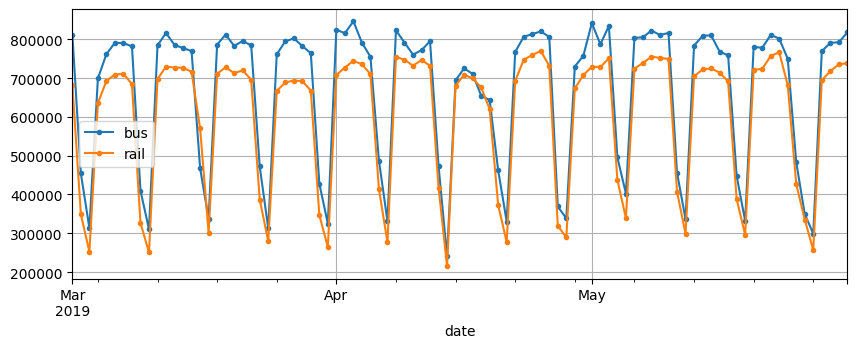

In [3]:
df['2019-03':'2019-05'].plot(grid=True, marker='.', figsize=(10,3.5))
plt.show()

Create the training, validation, and test sets

<Axes: ylabel='Frequency'>

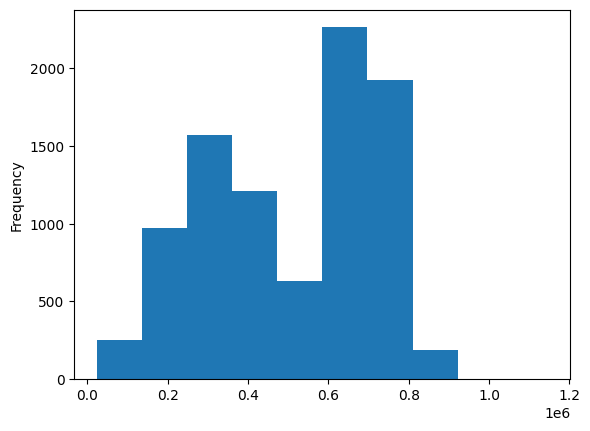

In [4]:
df['rail'].plot(kind='hist')

rail values: between 0 to 1 million: too large and we need to standardize these to ensure that gradient updates are stable

In [12]:
torch.manual_seed(1)

rail_train, rail_valid, rail_test = create_splits(df)

rail_train_chunks, rail_valid_chunks, rail_test_chunks = create_oned_chunks(56,rail_train), create_oned_chunks(56,rail_valid), create_oned_chunks(56,rail_test)

rail_train_ds, rail_valid_ds, rail_test_ds = TimeSeriesDataset(torch.tensor(rail_train_chunks)), TimeSeriesDataset(torch.tensor(rail_valid_chunks)), TimeSeriesDataset(torch.tensor(rail_test_chunks))

In [13]:
len(rail_train_ds), len(rail_valid_ds), len(rail_test_ds)

(1040, 95, 2228)

In [14]:
rail_train_dl = DataLoader(rail_train_ds, batch_size=128, shuffle=True)
rail_valid_dl = DataLoader(rail_valid_ds, batch_size=128)
rail_test_dl = DataLoader(rail_test_ds, batch_size=1024)

forecasting using a simple rnn:

In [15]:
class UnivarModel(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, 1)
    
    def forward(self, x):
        out, hn = self.rnn(x.unsqueeze(2))
        return self.linear(hn[-1, :, :])

In [16]:
device = torch.device("mps" if torch.mps.is_available() else "cpu")

In [18]:
torch.manual_seed(1)

univar_model = UnivarModel(1, 32).to(device)

optimizer = torch.optim.Adam(univar_model.parameters(), lr=0.02)

criterion = nn.HuberLoss(reduction='sum')

early_stopper = EarlyStopping(patience=50, checkpoint_path='univar_model2.pt', restore_best_weights=True, verbose=True)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5)

In [21]:
t_loss, v_loss = train_oned(500, univar_model, rail_train_dl, rail_valid_dl, device, criterion, optimizer, early_stopper, performance_scheduler=scheduler,other_scheduler=None, l1_norm=True, l1_lambda=0.03e-5)

Epoch: 1| Train loss: 0.0496| Val loss: 0.0374
Metric improved to 0.0374. Checkpoint saved at 0
Epoch: 2| Train loss: 0.0217| Val loss: 0.0247
Metric improved to 0.0247. Checkpoint saved at 1
Epoch: 3| Train loss: 0.0135| Val loss: 0.0148
Metric improved to 0.0148. Checkpoint saved at 2
Epoch: 4| Train loss: 0.0152| Val loss: 0.0126
Metric improved to 0.0126. Checkpoint saved at 3
Epoch: 5| Train loss: 0.0120| Val loss: 0.0085
Metric improved to 0.0085. Checkpoint saved at 4
Epoch: 6| Train loss: 0.0113| Val loss: 0.0161
No improvement for 1 epoch(s)
Epoch: 7| Train loss: 0.0196| Val loss: 0.0294
No improvement for 2 epoch(s)
Epoch: 8| Train loss: 0.0204| Val loss: 0.0208
No improvement for 3 epoch(s)
Epoch: 9| Train loss: 0.0699| Val loss: 0.0392
No improvement for 4 epoch(s)
Epoch: 10| Train loss: 0.0272| Val loss: 0.0147
No improvement for 5 epoch(s)
Epoch: 11| Train loss: 0.0167| Val loss: 0.0143
No improvement for 6 epoch(s)
Epoch: 12| Train loss: 0.0154| Val loss: 0.0142
No impro

In [22]:
# using the model to compute the mae on the test set
l1_loss = nn.L1Loss(reduction='sum')

loss_ = []

with torch.no_grad():
    for x_test_batch, y_test_batch in rail_test_dl:
        x_test_batch = x_test_batch.to(device)
        y_test_batch = y_test_batch.to(device)
        hn = univar_model(x_test_batch)
        loss = l1_loss(hn.squeeze(1), y_test_batch)
        loss_.append(loss.item())

In [23]:
sum(loss_)/len(rail_test_dl.dataset) * 1e6

84431.92690878411

**forecasting several steps ahead by naively feeding the predicted value back to the model**
- using both the validation and test sets
- rail_valid is from 2019-01 to 2019-05

In [24]:
# wan tto use ranges I can later compare to with factual data
rail_valid[:58].values

array([0.245852, 0.573542, 0.627781, 0.628514, 0.348257, 0.260556,
       0.66247 , 0.701693, 0.685444, 0.690162, 0.679115, 0.325219,
       0.250222, 0.705571, 0.720095, 0.728048, 0.734929, 0.700006,
       0.312424, 0.236744, 0.401503, 0.712125, 0.718899, 0.7113  ,
       0.590674, 0.296063, 0.221081, 0.67881 , 0.579917, 0.097917,
       0.243912, 0.648091, 0.34565 , 0.250724, 0.718764, 0.734181,
       0.727769, 0.732351, 0.655823, 0.338847, 0.251192, 0.704667,
       0.698387, 0.728764, 0.746611, 0.687932, 0.362613, 0.256817,
       0.519409, 0.725195, 0.717172, 0.727504, 0.702988, 0.328179,
       0.240478, 0.680844, 0.699462, 0.711827])

In [29]:
rail_valid.shape

(151,)

In [30]:
58-151

-93

In [27]:
pred_set = rail_valid[:58].values.tolist()

In [31]:
# using 93 because that is the difference between the chosen 58 values (first 58) and the rest of the series (valid set)
univar_model.eval()
with torch.no_grad():
    for i in range(93):
        result = univar_model(torch.tensor(pred_set[-56:]).view(1, -1).float().to(device))
        pred_set.append(result.detach().item())

In [32]:
len(pred_set)

151

In [33]:
pred_set_emb = pd.Series(pred_set, index=rail_valid.index)

<Axes: xlabel='date'>

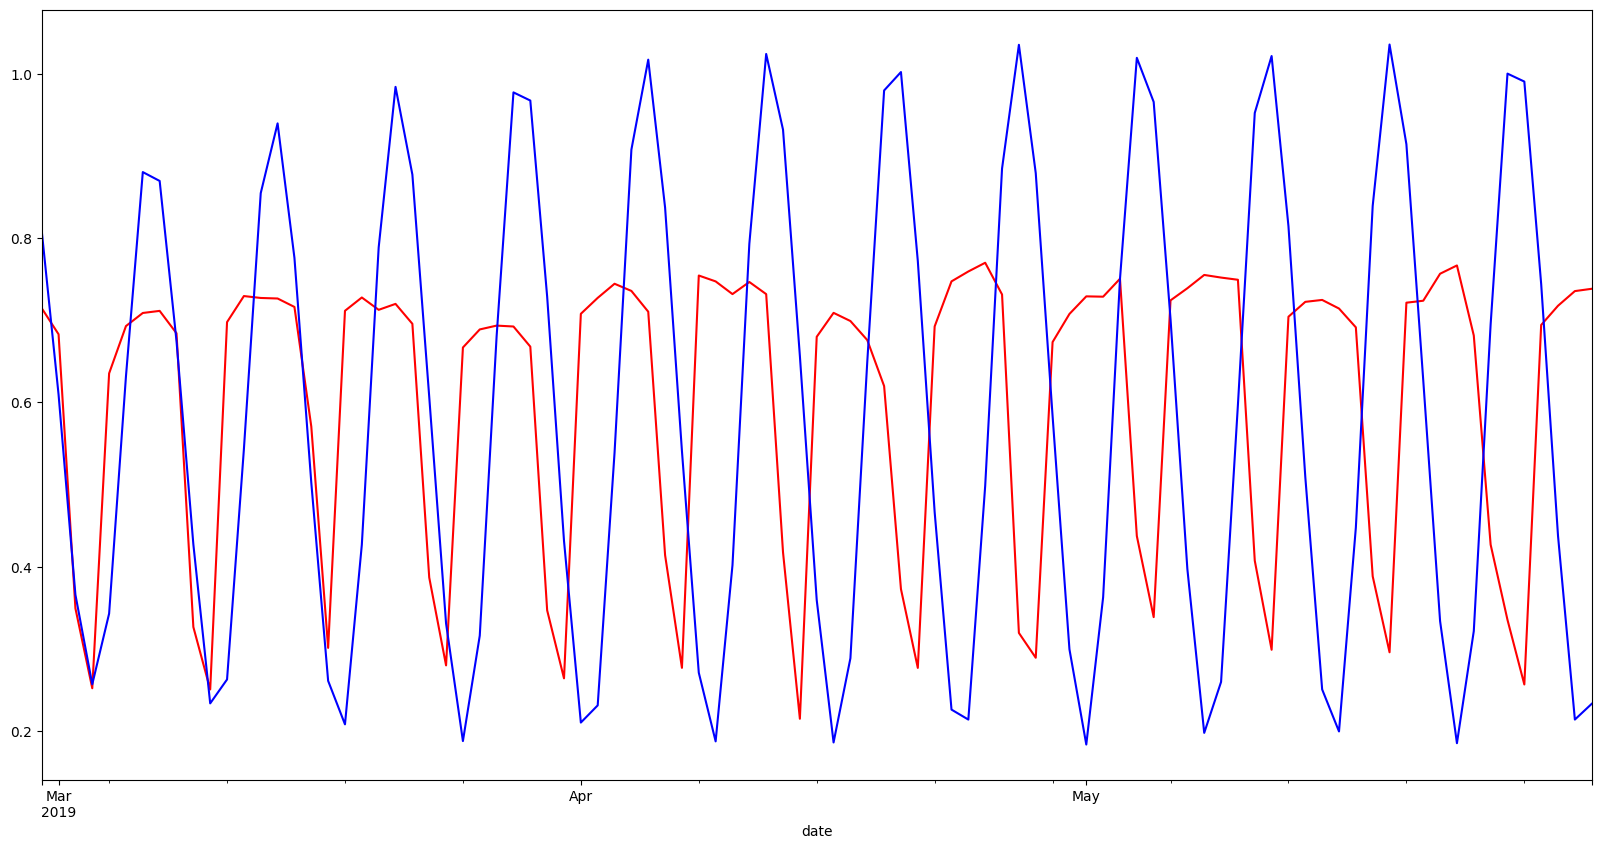

In [34]:
fig, ax = plt.subplots(figsize=(20,10))

rail_valid[58:].plot(ax=ax, color='red', label='truth')
pred_set_emb[58:].plot(ax=ax, color='blue',label='pred')

In [36]:
from utils.fetch_data import create_multidim_chunks2, create_splits_mulvar, train_encoder, transform_split, fetch_timeseries_data
from utils.load_data import TimeSeriesDataset2
from utils.train_model import train_multi_d
import importlib
import utils.fetch_data as fd
importlib.reload(fd)
transform_split = fd.transform_split

using a many-to-one architecture for forecasting over multiple timesteps by feeding the model's previous preds back to itself reinforces the model's errors and is not ideal...
- we need an actual sequence to vector model: (training an rnn to predict the next 14 values in one shot) - still using a sequence to vector model but outputting 14 values instead of 1. 

In [37]:
mulvar_train, mulvar_valid, mulvar_test = create_splits_mulvar(df)

In [38]:
mulvar_train.head(3)

,bus,rail,next_day_type
date,,,
2016-01-01,0.303321,0.319835,A
2016-01-02,0.448859,0.365509,U
2016-01-03,0.340540,0.287661,W


In [39]:
# train a onehot encoder on the categorical datatype
encoder = train_encoder(mulvar_train)

In [40]:
# get the transformed dataframes with the onehot encoded integers added
mulvar_train, mulvar_valid, mulvar_test = transform_split(mulvar_train, encoder), transform_split(mulvar_valid, encoder), transform_split(mulvar_test, encoder)

In [41]:
mulvar_train.head(3)

,bus,rail,next_day_type_A,next_day_type_U,next_day_type_W
date,,,,,
2016-01-01,0.303321,0.319835,1.0,0.0,0.0
2016-01-02,0.448859,0.365509,0.0,1.0,0.0
2016-01-03,0.340540,0.287661,0.0,0.0,1.0


In [42]:
# create the chunks necessary for training
mv_train_chunks, mv_valid_chunks, mv_test_chunks = create_multidim_chunks2(56, mulvar_train, 14), create_multidim_chunks2(56, mulvar_valid, 14), create_multidim_chunks2(56, mulvar_test, 14)

In [44]:
mv_train_chunks[0]

array([[0.303321, 0.319835, 1.      , 0.      , 0.      ],
       [0.448859, 0.365509, 0.      , 1.      , 0.      ],
       [0.34054 , 0.287661, 0.      , 0.      , 1.      ],
       [0.829429, 0.703185, 0.      , 0.      , 1.      ],
       [0.846789, 0.727716, 0.      , 0.      , 1.      ],
       [0.853904, 0.733167, 0.      , 0.      , 1.      ],
       [0.846274, 0.736809, 0.      , 0.      , 1.      ],
       [0.841494, 0.732495, 1.      , 0.      , 0.      ],
       [0.469539, 0.391597, 0.      , 1.      , 0.      ],
       [0.306896, 0.263073, 0.      , 0.      , 1.      ],
       [0.753006, 0.694734, 0.      , 0.      , 1.      ],
       [0.760149, 0.705694, 0.      , 0.      , 1.      ],
       [0.78722 , 0.716663, 0.      , 0.      , 1.      ],
       [0.859099, 0.758116, 0.      , 0.      , 1.      ],
       [0.858032, 0.742622, 1.      , 0.      , 0.      ],
       [0.486797, 0.404212, 0.      , 1.      , 0.      ],
       [0.266532, 0.24116 , 0.      , 0.      , 1.      

In [45]:
mv_train_chunks[0].shape

(70, 5)

- chunk above is of shape: (70,5)
- 5 dimensions because this is a multidimensional timeseries problem
- 70 dimensions along axis 0, (56 is the sequence length to be used by the model), and the rest 14 (values - sequence length) are the 14 vector values to be predicted on by the model (by this sequence to vector model)

essentially, this is what the dataset class below will do, for each example split each chunk and return x and y as follows:

In [46]:
seq_length = 56
x = mv_train_chunks[0][:seq_length, :]
y = mv_train_chunks[0][seq_length:, 1] # choosing 1 as the column cuz we're predicting 14 future values for the railway caategory which is col 1

In [47]:
x.shape, y.shape

((56, 5), (14,))

In [48]:
mv_train_ds = TimeSeriesDataset2(torch.tensor(np.array(mv_train_chunks), dtype=torch.float32), seq_length=56)
mv_valid_ds = TimeSeriesDataset2(torch.tensor(np.array(mv_valid_chunks), dtype=torch.float32), seq_length=56)
mv_test_ds = TimeSeriesDataset2(torch.tensor(np.array(mv_test_chunks), dtype=torch.float32), seq_length=56)

In [49]:
mv_train_dl = DataLoader(mv_train_ds, batch_size=64, shuffle=True)
mv_valid_dl = DataLoader(mv_valid_ds, batch_size=64)
mv_test_dl = DataLoader(mv_test_ds, batch_size=1024)

In [50]:
device = torch.device("mps" if torch.mps.is_available() else "cpu")

In [51]:
class UnivarModel2(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, 14)
    
    def forward(self, x):
        out, hn = self.rnn(x)
        return self.linear(hn[-1, :, :])

In [52]:
torch.manual_seed(1)
univar_model2 = UnivarModel2(5, 32).to(device)

In [53]:
optimizer = torch.optim.Adam(univar_model2.parameters(), lr=0.02)
criterion = nn.HuberLoss(reduction='sum')
early_stopper = EarlyStopping(patience=50, checkpoint_path = 'univar_model3.pt', restore_best_weights=True, verbose=True)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',patience=5)

In [54]:
t_loss, v_loss = train_multi_d(500, univar_model2, mv_train_dl, mv_valid_dl, device, criterion, optimizer, early_stopper, performance_scheduler=scheduler,other_scheduler=None, l1_norm=True, l1_lambda=3.0e-5)

Epoch: 1| Train loss: 0.5905| Val loss: 0.1396
Metric improved to 0.1396. Checkpoint saved at 0
Epoch: 2| Train loss: 0.1122| Val loss: 0.0464
Metric improved to 0.0464. Checkpoint saved at 1
Epoch: 3| Train loss: 0.0665| Val loss: 0.0320
Metric improved to 0.0320. Checkpoint saved at 2
Epoch: 4| Train loss: 0.0557| Val loss: 0.0293
Metric improved to 0.0293. Checkpoint saved at 3
Epoch: 5| Train loss: 0.0530| Val loss: 0.0330
No improvement for 1 epoch(s)
Epoch: 6| Train loss: 0.0530| Val loss: 0.0293
No improvement for 2 epoch(s)
Epoch: 7| Train loss: 0.0514| Val loss: 0.0221
Metric improved to 0.0221. Checkpoint saved at 6
Epoch: 8| Train loss: 0.0500| Val loss: 0.0384
No improvement for 1 epoch(s)
Epoch: 9| Train loss: 0.0548| Val loss: 0.0304
No improvement for 2 epoch(s)
Epoch: 10| Train loss: 0.0522| Val loss: 0.0309
No improvement for 3 epoch(s)
Epoch: 11| Train loss: 0.0548| Val loss: 0.0248
No improvement for 4 epoch(s)
Epoch: 12| Train loss: 0.0513| Val loss: 0.0214
Metric i

checking out the mae loss

In [55]:
l1_loss = nn.L1Loss(reduction='sum')
univar_model2.eval()
loss_ = []

with torch.no_grad():
    for x_test_batch, y_test_batch in mv_test_dl:
        x_test_batch = x_test_batch.to(device)
        y_test_batch = y_test_batch.to(device)
        hn = univar_model2(x_test_batch)
        loss = l1_loss(hn, y_test_batch)
        loss_.append(loss.item())

In [56]:
sum(loss_)/len(mv_test_dl.dataset)*1e6

2061525.394815309

Predictions on the test set

In [57]:
mulvar_test

,bus,rail,next_day_type_A,next_day_type_U,next_day_type_W
date,,,,,
2019-06-01,0.473204,0.379044,0.0,1.0,0.0
2019-06-02,0.370049,0.319334,0.0,0.0,1.0
2019-06-03,0.814607,0.731571,0.0,0.0,1.0
2019-06-04,0.797511,0.749759,0.0,0.0,1.0
2019-06-05,0.817943,0.764911,0.0,0.0,1.0
...,...,...,...,...,...
2025-08-26,0.645971,0.465834,0.0,0.0,1.0
2025-08-27,0.653421,0.473422,0.0,0.0,1.0
2025-08-28,0.642222,0.520735,0.0,0.0,1.0


In [69]:
seq_length = 56
forecasting_horizon = 14

chunk_size = seq_length + forecasting_horizon

preds = []
univar_model2.eval()

for i in range(mulvar_test.shape[0]):
    if i*chunk_size+seq_length <= mulvar_test.shape[0]:
        #print(i*chunk_size, i*chunk_size+seq_length)
        chunk = mulvar_test.iloc[i*chunk_size:i*chunk_size+seq_length, :].values
        preds += mulvar_test.iloc[i*chunk_size:i*chunk_size+seq_length, :].values[:, 1].tolist()
        chunk = torch.tensor(chunk, dtype=torch.float32).unsqueeze(0).to(device)

        with torch.no_grad():
            out = univar_model2(chunk)
            out = out.view(-1).cpu().numpy().tolist()
            preds += out

    # break


In [70]:
len(preds)

2240

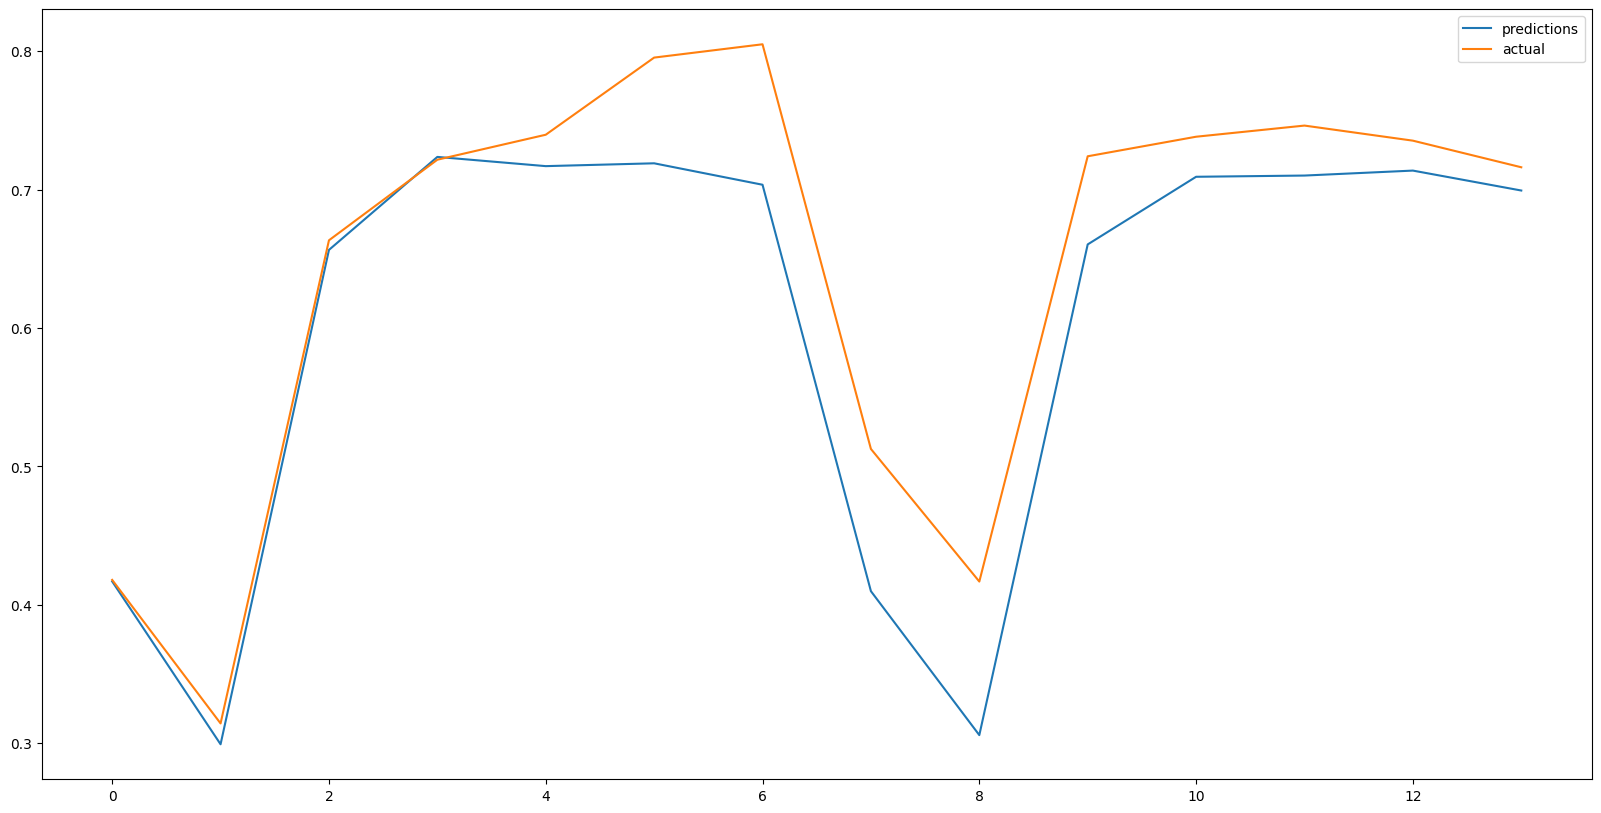

In [79]:
fig, ax = plt.subplots(figsize=(20,10))
ax.plot(preds[56:70], label = 'predictions')
actual = mulvar_test['rail'][56:70].values.tolist()
ax.plot(actual, label='actual')
ax.legend()

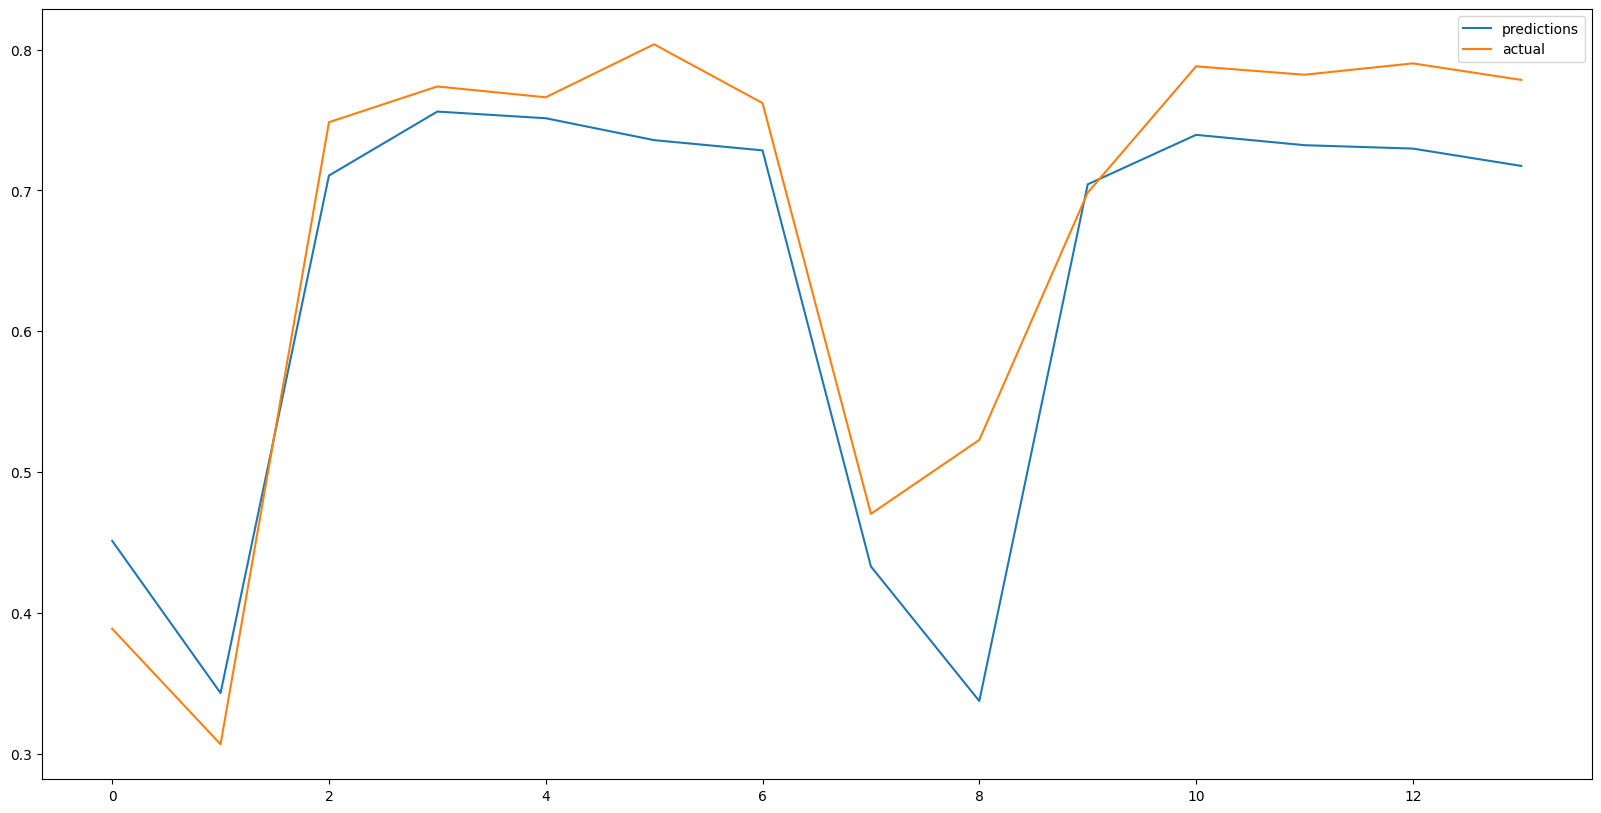

In [80]:
fig, ax = plt.subplots(figsize=(20,10))
ax.plot(preds[126:140], label = 'predictions')
actual = mulvar_test['rail'][126:140].values.tolist()
ax.plot(actual, label='actual')
ax.legend()

**above technique is better than feeding the errors back into the model

**even bettter is a sequence to sequence model:**
- instead of training the rnn to forecast the next 14 values only at the very last timestep, we can train it to forecast the next 14 values at each and every timestep.  In otherwords, we can turn this sequence to vector rnn into a sequence to sequence rnn. the advantage being that the loss will contain a term for the output of the rnn at each and every timestep, not just the output at the last timestep
- implying that there will be more error gradients flowing through the model, and they won't have to flow through time as much since they will come from the output of each timestep, not just the last one
- to be clear, at timestep 0, the model will output a vector containing the forecasts for timestep 1 to 14. then at timestep 1 the forecast from timesteps 2 to 15, and so on....the targets are sequences of consecutive windows shifted by one timestep at each timestep. the target isn't a vector anymore but a sequence of the same length as the inputs containing a 14-dimensional vector at each timestep. 

In [81]:
df = fetch_timeseries_data()
rail_train, rail_valid, rail_test = create_splits(df)

In [84]:
# creating chunks
sequence_length = 56
forecasting_horizon = 14
train_x_chunks = [rail_train.values.tolist()[i:i+sequence_length] for i in range(len(rail_train.values.tolist()) - sequence_length - forecasting_horizon + 1)]

In [85]:
torch.tensor(train_x_chunks).shape

torch.Size([1027, 56])

In [86]:
train_y_chunks = []

for i in range(len(rail_train.values.tolist()) - sequence_length - forecasting_horizon + 1):
    train_y_chunks.append(
        [
            rail_train.values.tolist()[i+j+1:i+j+1+14] for j in range(56)
        ]
    )

In [90]:
train_x_chunks = torch.tensor(train_x_chunks)
train_y_chunks = torch.tensor(train_y_chunks)

created training dataset chunks of appropriate sizes...need to do the same thing for the validation and test sets

In [92]:
valid_x_chunks = [rail_valid.values.tolist()[i:i+sequence_length] for i in range(len(rail_valid.values.tolist()) - sequence_length - forecasting_horizon + 1)]
valid_x_chunks = torch.tensor(valid_x_chunks)

In [93]:
valid_x_chunks.shape

torch.Size([82, 56])

In [94]:
valid_y_chunks = []

for i in range(len(rail_valid.values.tolist()) - sequence_length - forecasting_horizon + 1):
    valid_y_chunks.append(
        [rail_valid.values.tolist()[i+j+1:i+j+1+forecasting_horizon] for j in range(sequence_length)]
    )

valid_y_chunks = torch.tensor(valid_y_chunks)

In [95]:
valid_y_chunks.shape

torch.Size([82, 56, 14])

In [96]:
# same for the test dataset
test_x_chunks = [rail_test.values.tolist()[i:i+sequence_length] for i in range(len(rail_test.values.tolist()) - sequence_length - forecasting_horizon + 1)]
test_x_chunks = torch.tensor(test_x_chunks)

test_y_chunks = []

for i in range(len(rail_test.values.tolist()) - sequence_length - forecasting_horizon + 1):
    test_y_chunks.append(
        [rail_test.values.tolist()[i+j+1:i+j+1+forecasting_horizon] for j in range(sequence_length)]
    )

test_y_chunks = torch.tensor(test_y_chunks)

In [97]:
test_x_chunks.shape, test_y_chunks.shape

(torch.Size([2215, 56]), torch.Size([2215, 56, 14]))

**Batch the data:**

In [98]:
class SequenceDataset(Dataset):
    def __init__(self, x_chunks, y_chunks):
        self.x_chunks = x_chunks.unsqueeze(2)
        self.y_chunks = y_chunks
    
    def __len__(self):
        return self.x_chunks.shape[0]
    
    def __getitem__(self, index):
        c_x = self.x_chunks[index]
        c_y = self.y_chunks[index]
        return c_x, c_y

In [100]:
train_ds = SequenceDataset(train_x_chunks, train_y_chunks)
val_ds = SequenceDataset(valid_x_chunks, valid_y_chunks)
test_ds = SequenceDataset(test_x_chunks, test_y_chunks)

In [101]:
a , b = train_ds[0]

In [102]:
a.shape, b.shape

(torch.Size([56, 1]), torch.Size([56, 14]))

In [103]:
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=128)
test_dl = DataLoader(test_ds, batch_size=1024)

Build the model:

In [110]:
importlib.reload(train_mod)
train_oned2 = train_mod.train_oned2

In [111]:
class Seq2SeqUnivar(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.rnn = nn.LSTM(input_size, hidden_size, batch_first=True, num_layers=1)
        self.linear = nn.Linear(hidden_size, 14)
    def forward(self, input):
        out, (_, _) = self.rnn(input)
        return self.linear(out)

device = torch.device("mps" if torch.mps.is_available() else "cpu")

torch.manual_seed(1)

seq2seq = Seq2SeqUnivar(1, 32).to(device)

# the optimizer
optimizer = torch.optim.AdamW(seq2seq.parameters(), lr=0.001)
criterion = nn.HuberLoss(reduction='sum')
early_stopper = EarlyStopping(patience=50, checkpoint_path = 'seq2seq.pt', restore_best_weights=True, verbose=True)
scheduler2 = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.85)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',patience=5)

In [112]:
t_loss, v_loss = train_oned2(500, seq2seq, train_dl, val_dl, device, criterion, optimizer, early_stopper, performance_scheduler=scheduler,other_scheduler=None)

Epoch: 1| Train loss: 185.4847| Val loss: 150.3638
Metric improved to 150.3638. Checkpoint saved at 0
Epoch: 2| Train loss: 164.7680| Val loss: 131.1478
Metric improved to 131.1478. Checkpoint saved at 1
Epoch: 3| Train loss: 142.0518| Val loss: 106.7283
Metric improved to 106.7283. Checkpoint saved at 2
Epoch: 4| Train loss: 109.8175| Val loss: 68.2214
Metric improved to 68.2214. Checkpoint saved at 3
Epoch: 5| Train loss: 59.7066| Val loss: 33.1999
Metric improved to 33.1999. Checkpoint saved at 4
Epoch: 6| Train loss: 33.5716| Val loss: 29.1194
Metric improved to 29.1194. Checkpoint saved at 5
Epoch: 7| Train loss: 23.5130| Val loss: 19.3826
Metric improved to 19.3826. Checkpoint saved at 6
Epoch: 8| Train loss: 19.5776| Val loss: 18.2485
Metric improved to 18.2485. Checkpoint saved at 7
Epoch: 9| Train loss: 19.0207| Val loss: 18.5993
No improvement for 1 epoch(s)
Epoch: 10| Train loss: 18.5259| Val loss: 18.4979
No improvement for 2 epoch(s)
Epoch: 11| Train loss: 18.1244| Val los

In [113]:
l1_loss = nn.L1Loss(reduction='sum')
loss_ = []

with torch.no_grad():
    seq2seq.eval()
    for x_batch, y_batch in test_dl:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        out = seq2seq(x_batch)
        loss = l1_loss(out, y_batch)
        loss_.append(loss.item())

In [115]:
sum(loss_)/len(test_dl.dataset) * 1e6

144461646.44469523

In [142]:
pred_set = torch.tensor(rail_test.iloc[70:126].values.tolist(), device=device).unsqueeze(0).unsqueeze(2)

In [143]:
pred_set.shape

torch.Size([1, 56, 1])

In [144]:
with torch.no_grad():
    prediction = seq2seq(pred_set)

In [145]:
prediction.shape

torch.Size([1, 56, 14])

In [135]:
prediction[-1, -1, :]

tensor([0.4317, 0.3363, 0.6636, 0.7360, 0.7197, 0.7386, 0.7244, 0.4240, 0.3359,
        0.6659, 0.7574, 0.7191, 0.7424, 0.7156], device='mps:0')

In [140]:
prediction[-1, -1, :]

tensor([0.4415, 0.3524, 0.6834, 0.7625, 0.7344, 0.7677, 0.7445, 0.4316, 0.3566,
        0.6909, 0.7759, 0.7363, 0.7672, 0.7331], device='mps:0')

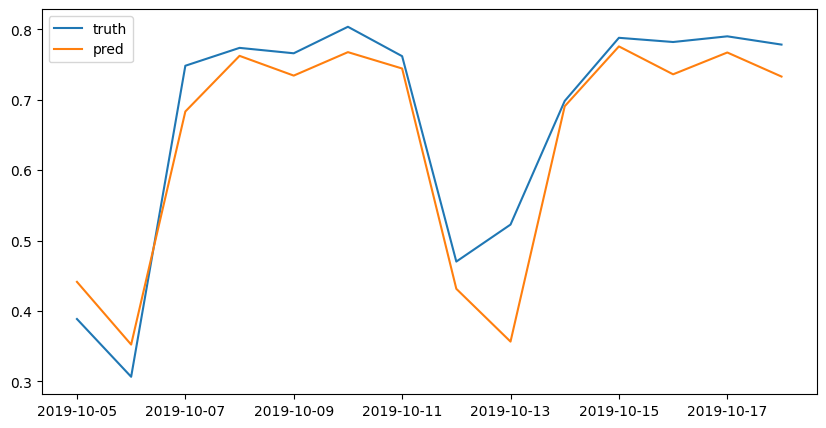

In [147]:
fig, ax = plt.subplots(1,1,figsize=(10,5))
ax.plot(rail_test.iloc[126:126+14],label='truth')
ax.plot(
    pd.Series(
    prediction[-1, -1, :].detach().cpu().numpy(),
    index = rail_test.iloc[126:126+14].index
),label='pred'
)
ax.legend()